# Diseño de completación y productividad de pozos no convencionales en Vaca Muerta

## Proyecto Final — Pre-entrega 4: aprendizaje no supervisado

**Integrantes:** Franco Malacalza · Martín Gerbaldo · Carolina Bailón

**Curso:** EnergIA Digital 2026 — Ciencia de Datos

---

## De dónde venimos

Las tres entregas anteriores fueron **supervisadas**: teníamos una respuesta conocida —cuántos metros
cúbicos produjo cada pozo— y entrenamos modelos para predecirla, primero como número (regresión) y
después como categoría (clasificación).

Esta entrega cambia la pregunta. Acá **no hay respuesta conocida**: le damos al algoritmo solamente
el diseño de completación de cada pozo y le pedimos que, mirando nada más que eso, nos diga si los
pozos se parecen entre sí de alguna forma sistemática.

> **¿Existen "tipos" de diseño de completación, o cada pozo se diseña distinto?**

Y una segunda pregunta que convierte al ejercicio en algo verificable:

> **Si esos tipos existen, ¿producen distinto?** Los grupos se van a formar **sin mirar la
> producción**, así que comparar la producción entre grupos después es una validación honesta: nada
> del objetivo entró al ajuste.

## Qué cambia respecto de las entregas anteriores

| | Pre-entregas 2 y 3 | Esta |
|---|---|---|
| **Tipo de aprendizaje** | supervisado | **no supervisado** |
| **Variable objetivo** | producción a 12 meses | **ninguna** |
| **Qué se evalúa** | error contra la respuesta correcta | cohesión y separación de los grupos |
| **Pozos disponibles** | 1.917 (los que tienen producción medida) | **2.603** (todos los del alcance) |
| **Riesgo principal** | sobreajuste | encontrar grupos donde no los hay |

El salto de 1.917 a 2.603 pozos no es un detalle: son **686 pozos más**, un 36% adicional. Los
habíamos tenido que dejar afuera porque todavía no cumplieron doce meses de producción o porque son
pozos de gas. Para agrupar por diseño no hace falta saber cuánto produjeron, así que vuelven a
entrar.

## Resumen ejecutivo

Los cuatro hallazgos de esta entrega:

1. **Los pozos sí se agrupan solos, en cuatro familias de diseño**, y cada una corresponde a una
   forma reconocible de completar un pozo: intensivo moderno, intermedio, de arena importada y de
   baja intensidad. No hubo que inventar las categorías: salieron de los datos.

2. **Las familias ordenan la producción sin haberla visto.** Las medianas van de **36.760 m³** en el
   grupo intensivo a **3.311 m³** en el de baja intensidad, en el mismo orden que la intensidad del
   diseño (Kruskal-Wallis p ≈ 5·10⁻⁵⁷). Es la validación externa del punto 14.

3. **Sin tratar los extremos, el algoritmo gasta grupos enteros en tres pozos.** La silueta sube a
   0,63 y parece un éxito: es exactamente al revés. Es el mismo tipo de trampa métrica que la
   partición aleatoria de la Pre-entrega 3, y está documentado en el punto 5.

4. **`ratio_arena_importada` define una familia entera**, la misma variable que los modelos
   supervisados declararon inservible para predecir (+79 m³, importancia 0,0000). Una variable puede
   no servir para predecir y sí para describir: son preguntas distintas.


# Parte 1: Datos y variables

# 1. Preparación del entorno

Mismas versiones y misma semilla que los notebooks anteriores. Las funciones compartidas se importan
de `src/utils.py`.


In [1]:
import warnings

# Se silencian solo las dos categorias que ensucian la salida sin indicar un problema
# real: avisos de que una API de pandas o de scikit-learn va a cambiar en una version
# futura. Un RuntimeWarning SI tiene que aparecer, y por eso no se apaga todo.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import kruskal
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

# Las funciones que comparten los cuatro cuadernos viven en src/utils.py, asi el
# analisis se lee sin la plomeria. Si el cuaderno se abre en Colab, donde el
# repositorio no esta clonado, el modulo se baja igual que los datos.
URL_UTILS = ("https://raw.githubusercontent.com/FrancoMalacalza01/"
             "preentrega-data-science/main/src/utils.py")
RAIZ = next((p for p in (Path(".."), Path("."))
             if (p / "src" / "utils.py").exists()), None)
if RAIZ is None:
    import urllib.request
    Path("src").mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL_UTILS, "src/utils.py")
    RAIZ = Path(".")
sys.path.insert(0, str(RAIZ))

from src.utils import leer, f3, agrupar_categorias

SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", f3)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

print(f"pandas       {pd.__version__}")
print(f"numpy        {np.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"semilla      {SEMILLA}")


pandas       3.0.5
numpy        2.5.3
scikit-learn 1.9.1
semilla      42


# 2. Reconstrucción del dataset

Este notebook se sostiene solo: vuelve a aplicar la misma tubería de los notebooks 02 y 03, desde los
archivos originales. El detalle de cada decisión —el alcance de 500 m, la consolidación de cargas
parciales, la imputación por mediana de formación— está documentado allá.

**La diferencia importante está en dónde corta.** Los notebooks supervisados se quedaban con los
1.917 pozos que tienen doce meses completos de producción medida y no son pozos de gas. Acá el
clustering no necesita la variable objetivo, así que trabajamos sobre los **2.603 pozos del alcance**.
La producción se carga igual, pero **se reserva**: no entra al ajuste y se usa recién en el punto 14
para validar desde afuera.


In [2]:
print("Leyendo:")
fractura = leer("fractura_adjunto_iv.csv", low_memory=False)
prod = leer("produccion_filtrada.csv.gz")


Leyendo:
  fractura_adjunto_iv.csv          <- ../data/fractura_adjunto_iv.csv
  produccion_filtrada.csv.gz       <- ../data/produccion_filtrada.csv.gz


In [3]:
UMBRAL_RAMA_M = 500
CATEGORICAS = ["cuenca", "formacion_productiva", "tipo_reservorio", "subtipo_reservorio",
               "tipo_terminacion", "empresa_informante", "yacimiento", "areapermisoconcesion"]
AGREGACION = {
    "longitud_rama_horizontal_m": "max", "presion_maxima_psi": "max",
    "potencia_equipos_fractura_hp": "max", "cantidad_fracturas": "sum",
    "arena_bombeada_nacional_tn": "sum", "arena_bombeada_importada_tn": "sum",
    "agua_inyectada_m3": "sum", "fecha_inicio_fractura": "min", "fecha_fin_fractura": "max",
    "sigla": "first", "cuenca": "first", "areapermisoconcesion": "first", "yacimiento": "first",
    "formacion_productiva": "first", "tipo_reservorio": "first", "subtipo_reservorio": "first",
    "tipo_terminacion": "first", "empresa_informante": "first",
}

df = fractura.copy()
for c in ["fecha_inicio_fractura", "fecha_fin_fractura", "fecha_data"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

# La referencia para descartar fechas imposibles sale del propio archivo, no del reloj.
FECHA_CORTE = df.fecha_data.max()
df.loc[df.fecha_fin_fractura < df.fecha_inicio_fractura, "fecha_fin_fractura"] = pd.NaT
df.loc[df.fecha_inicio_fractura > FECHA_CORTE, "fecha_inicio_fractura"] = pd.NaT

for c in CATEGORICAS:
    df[c] = (df[c].astype(str).str.strip().str.lower()
             .replace({"nan": "sin dato", "": "sin dato"}))

df = df[df.longitud_rama_horizontal_m >= UMBRAL_RAMA_M]
pozos = df.groupby("idpozo").agg(**{k: (k, v) for k, v in AGREGACION.items()}).reset_index()

# Imputacion de ceros centinela y de los extremos del 1%, por mediana de formacion.
for c in ["presion_maxima_psi", "potencia_equipos_fractura_hp", "agua_inyectada_m3"]:
    falta = (pozos[c] == 0) | pozos[c].isna()
    mediana = pozos.loc[~falta].groupby("formacion_productiva")[c].median()
    pozos.loc[falta, c] = pozos.loc[falta, "formacion_productiva"].map(mediana)
    pozos[c] = pozos[c].fillna(pozos.loc[~falta, c].median())
for c in ["presion_maxima_psi", "potencia_equipos_fractura_hp"]:
    lo, hi = pozos[c].quantile([0.01, 0.99])
    extremo = (pozos[c] < lo) | (pozos[c] > hi)
    mediana = pozos.loc[~extremo].groupby("formacion_productiva")[c].median()
    pozos.loc[extremo, c] = pozos.loc[extremo, "formacion_productiva"].map(mediana)
    pozos[c] = pozos[c].fillna(pozos.loc[~extremo, c].median())

# Variables de intensidad: el aporte de feature engineering de la Pre-entrega 2.
pozos["arena_total_tn"] = pozos.arena_bombeada_nacional_tn + pozos.arena_bombeada_importada_tn
pozos["arena_por_metro"] = pozos.arena_total_tn / pozos.longitud_rama_horizontal_m
pozos["agua_por_metro"] = pozos.agua_inyectada_m3 / pozos.longitud_rama_horizontal_m
pozos["espaciamiento_etapas_m"] = pozos.longitud_rama_horizontal_m / pozos.cantidad_fracturas
pozos["ratio_arena_importada"] = (pozos.arena_bombeada_importada_tn
                                  / pozos.arena_total_tn.replace(0, np.nan)).fillna(0)
pozos["ratio_agua_arena"] = pozos.agua_inyectada_m3 / pozos.arena_total_tn.replace(0, np.nan)
pozos["anio_fractura"] = pozos.fecha_inicio_fractura.dt.year
pozos["operadora"] = agrupar_categorias(pozos.empresa_informante)

print(f"Fecha de publicacion del archivo: {FECHA_CORTE:%Y-%m-%d}")
print(f"Pozos del alcance, consolidados:  {len(pozos):,}")


Fecha de publicacion del archivo: 2026-09-04
Pozos del alcance, consolidados:  2,603


In [4]:
# La produccion se carga pero NO entra al clustering: queda reservada para el punto 14.
prod["periodo"] = pd.to_datetime(dict(year=prod.anio, month=prod.mes, day=1)).dt.to_period("M")
activos = prod[prod.prod_pet > 0].copy()
primer_mes = activos.groupby("idpozo").periodo.min().rename("primer_mes")
activos = activos.merge(primer_mes, on="idpozo")
activos["mes_de_vida"] = ((activos.periodo.dt.year - activos.primer_mes.dt.year) * 12
                          + (activos.periodo.dt.month - activos.primer_mes.dt.month) + 1)
ventana = activos[activos.mes_de_vida.between(1, 12)]
objetivo = ventana.groupby("idpozo").agg(
    prod_pet_acum_12m=("prod_pet", "sum"), prod_gas_acum_12m=("prod_gas", "sum"),
    primer_mes=("primer_mes", "first")).reset_index()

p_min, p_max = prod.periodo.min(), prod.periodo.max()
objetivo = objetivo[~(objetivo.primer_mes <= p_min) & ~((objetivo.primer_mes + 11) > p_max)].copy()
objetivo["ratio_gas_pet"] = (objetivo.prod_gas_acum_12m
                             / objetivo.prod_pet_acum_12m.replace(0, np.nan))
objetivo["es_pozo_de_gas"] = ((objetivo.prod_pet_acum_12m < 1000)
                              & (objetivo.ratio_gas_pet > 5)).astype(int)

pozos = pozos.merge(objetivo[["idpozo", "prod_pet_acum_12m", "es_pozo_de_gas"]],
                    on="idpozo", how="left")

con_objetivo = pozos.prod_pet_acum_12m.notna() & (pozos.es_pozo_de_gas == 0)
print(f"Pozos para agrupar (todo el alcance):        {len(pozos):,}")
print(f"De esos, con produccion medida y de petroleo: {con_objetivo.sum():,}"
      f"   <- los que usaron los notebooks 02 y 03")
print(f"Pozos que esta entrega suma:                  {len(pozos) - con_objetivo.sum():,}")


Pozos para agrupar (todo el alcance):        2,603
De esos, con produccion medida y de petroleo: 1,917   <- los que usaron los notebooks 02 y 03
Pozos que esta entrega suma:                  686


# 3. Qué variables entran, y por qué

Acá hay una decisión de fondo. Si agrupamos usando la **escala** del pozo —metros de rama, toneladas
totales de arena— los grupos van a separar pozos grandes de pozos chicos, que es algo que ya sabemos
y que no hace falta un algoritmo para descubrir.

Lo que queremos saber es otra cosa: **cómo se fractura**, independientemente de cuán largo sea el
pozo. Para eso están las variables de intensidad que construimos en la Pre-entrega 2, que ya vienen
normalizadas por la escala:

| Variable | Qué mide | Por qué es de intensidad |
|---|---|---|
| `espaciamiento_etapas_m` | metros entre etapas | cuán denso se fractura, no cuántas etapas hay |
| `arena_por_metro` | toneladas de arena por metro de rama | cuánto apuntala por metro, no cuánta arena total |
| `agua_por_metro` | m³ de agua por metro de rama | ídem con el fluido |
| `ratio_agua_arena` | m³ de agua por tonelada de arena | la receta de la mezcla |
| `ratio_arena_importada` | proporción de arena importada | una decisión de abastecimiento |

Las cinco describen **la receta**, no el tamaño de la olla. Dos pozos de 1.500 y 4.000 metros con la
misma receta tienen que caer en el mismo grupo, y eso es exactamente lo que queremos.

Las variables de escala (`longitud_rama_horizontal_m`, `cantidad_fracturas`) y la producción quedan
afuera del ajuste, pero las guardamos para **caracterizar** los grupos después. Es una distinción
importante: una variable que no entra al modelo igual sirve para describir lo que el modelo encontró.


In [5]:
INTENSIDAD = ["espaciamiento_etapas_m", "arena_por_metro", "agua_por_metro",
              "ratio_agua_arena", "ratio_arena_importada"]
# Entran al ajuste solo las de intensidad. Estas otras son para describir despues.
DESCRIPTIVAS = ["longitud_rama_horizontal_m", "cantidad_fracturas", "anio_fractura"]

print(f"Variables que entran al clustering: {len(INTENSIDAD)}")
print(f"Nulos en esas variables: {pozos[INTENSIDAD].isna().sum().sum()}")
print()
print(pozos[INTENSIDAD].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).to_string())


Variables que entran al clustering: 5
Nulos en esas variables: 0

       espaciamiento_etapas_m  arena_por_metro  agua_por_metro  ratio_agua_arena  ratio_arena_importada
count                   2,603            2,603           2,603             2,603                  2,603
mean                   69.518            3.498          22.314             6.364                  0.073
std                    36.341            1.259           8.412             1.512                  0.202
min                    24.324            0.110           0.203             0.141                  0.000
1%                     39.118            0.322           1.431             2.368                  0.000
25%                    59.574            3.008          18.509             5.876                  0.000
50%                    63.243            3.625          22.576             6.213                  0.000
75%                    75.000            3.946          25.730             7.013                  0.00

Dos cosas saltan de la tabla y las dos importan para lo que sigue:

- **Las escalas no tienen nada que ver entre sí.** `agua_por_metro` vive alrededor de 22 y
  `ratio_arena_importada` entre 0 y 1. Una distancia euclídea calculada así estaría dominada casi por
  completo por el agua, y la arena importada no pesaría nada.
- **Las colas son largas.** El máximo de `espaciamiento_etapas_m` es 1.123 m contra una mediana de 63.
  El de `agua_por_metro`, 163 contra 23. Eso es lo que vamos a ver en el punto 5.


# Parte 2: Preparar los datos para una técnica basada en distancias

# 4. Por qué hay que estandarizar

K-Means agrupa por **distancia euclídea**: dos pozos son parecidos si están cerca en el espacio de
las cinco variables. Pero "cerca" depende de las unidades. Con las variables tal como están, una
diferencia de 10 m³/m de agua pesa diez mil veces más que una diferencia de 0,001 en la proporción de
arena importada, no porque sea más importante sino porque está medida en otra escala.

Estandarizar —restarle la media y dividir por el desvío a cada variable— pone a las cinco en pie de
igualdad. Es obligatorio en cualquier técnica basada en distancias, y es la diferencia con los
árboles de las entregas anteriores, a los que la escala les daba exactamente lo mismo.


In [6]:
escalador_crudo = StandardScaler()
X_crudo = escalador_crudo.fit_transform(pozos[INTENSIDAD])

comparacion = pd.DataFrame({
    "rango_original": pozos[INTENSIDAD].max() - pozos[INTENSIDAD].min(),
    "desvio_original": pozos[INTENSIDAD].std(),
    "desvio_estandarizado": X_crudo.std(axis=0),
})
print("Antes y despues de estandarizar:")
print(comparacion.to_string())


Antes y despues de estandarizar:
                        rango_original  desvio_original  desvio_estandarizado
espaciamiento_etapas_m           1,099           36.341                 1.000
arena_por_metro                 38.623            1.259                 1.000
agua_por_metro                 162.827            8.412                 1.000
ratio_agua_arena                29.010            1.512                 1.000
ratio_arena_importada            1.000            0.202                 1.000


# 5. Primer intento: el algoritmo encuentra tres pozos

Antes de refinar nada, corremos K-Means sobre las variables estandarizadas y miramos qué sale. Es el
camino honesto: primero el intento directo, después el diagnóstico.


In [7]:
filas = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=200, random_state=SEMILLA).fit(X_crudo)
    tam = pd.Series(km.labels_).value_counts().sort_values(ascending=False)
    filas.append({"k": k, "silueta": silhouette_score(X_crudo, km.labels_),
                  "grupo_mas_chico": tam.min(),
                  "tamaños": ", ".join(str(t) for t in tam.tolist()[:6])})
print("K-Means sobre las variables SIN tratar los extremos:\n")
print(pd.DataFrame(filas).set_index("k").to_string())


K-Means sobre las variables SIN tratar los extremos:

   silueta  grupo_mas_chico                   tamaños
k                                                    
2    0.632              221                 2382, 221
3    0.615                3              2375, 225, 3
4    0.350                3         1639, 825, 136, 3
5    0.359                2      1656, 806, 136, 3, 2
6    0.374                2   1683, 777, 135, 3, 3, 2
7    0.377                2  1633, 736, 138, 88, 3, 3


Con k=2 el resultado es razonable: 2.382 pozos contra 221. Pero apenas pedimos un grupo más, **el
tercero tiene 3 pozos**, y de k=5 en adelante aparecen grupos de 2. Mientras tanto la silueta se
mantiene altísima para datos reales —0,62 en k=3— y recién cae cuando los grupos chicos dejan de
dominar.

Las dos cosas son la misma cosa: la silueta premia que un grupo esté lejos de los demás y sea
compacto, y nada cumple eso mejor que un puñado de puntos extremos aislados en un rincón.

Veamos quiénes son esos tres pozos.


In [8]:
etiquetas_crudo = KMeans(n_clusters=3, n_init=200, random_state=SEMILLA).fit_predict(X_crudo)
mas_chico = pd.Series(etiquetas_crudo).value_counts().idxmin()
aislados = pozos.loc[etiquetas_crudo == mas_chico,
                     ["sigla", "anio_fractura"] + INTENSIDAD + ["longitud_rama_horizontal_m",
                                                                "cantidad_fracturas"]]
print(f"El grupo que K-Means separa con k=3 tiene {len(aislados)} pozos:\n")
print(aislados.to_string(index=False))


El grupo que K-Means separa con k=3 tiene 3 pozos:

             sigla  anio_fractura  espaciamiento_etapas_m  arena_por_metro  agua_por_metro  ratio_agua_arena  ratio_arena_importada  longitud_rama_horizontal_m  cantidad_fracturas
  CGC.SCA.CI-70(h)          2,018                   1,016            0.926           2.342             2.530                  1.000                       1,016                   1
  CGC.SCA.CI-98(h)          2,019                   1,123            0.573           2.135             3.729                  1.000                       1,123                   1
TPT.Nq.PPar-265(h)          2,024                 716.400            0.260           2.007             7.721                  0.000                       3,582                   5


Son pozos reales, no errores de carga: **dos de ellos se fracturaron en una sola etapa** sobre más de
mil metros de rama, y el tercero en cinco etapas sobre 3.582 m. Son operaciones excepcionales, y el
`espaciamiento_etapas_m` que les corresponde —716 a 1.123 metros entre etapas, contra una mediana de
63— los deja a una distancia enorme de todos los demás.

No son un problema de los datos: son un problema de la **técnica**. K-Means no tiene forma de decir
"estos tres son raros, los dejo aparte": si le pedimos tres grupos, va a gastar uno entero en ellos
y a meter los otros 2.600 pozos en los dos que quedan. Y la métrica nos va a felicitar por eso.

> Es el mismo tipo de trampa que encontramos en la Pre-entrega 3 con la partición aleatoria: **una
> métrica que mejora no siempre significa un modelo mejor**. Hay que mirar qué está premiando.


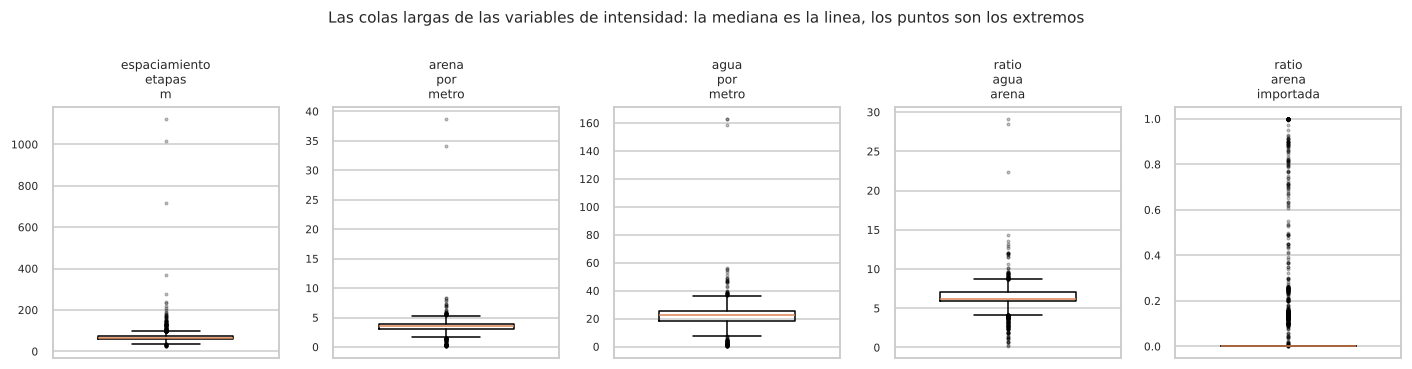

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.4))
for ax, c in zip(axes, INTENSIDAD):
    ax.boxplot(pozos[c].dropna(), widths=0.6,
               flierprops=dict(marker=".", markersize=3, alpha=0.35))
    ax.set_title(c.replace("_", "\n"), fontsize=8)
    ax.set_xticks([])
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Las colas largas de las variables de intensidad: la mediana es la linea, "
             "los puntos son los extremos", fontsize=10)
plt.tight_layout(); plt.show()


# 6. Acotar los extremos

La solución no es borrar esos pozos —son pozos reales y el dataset ya está acotado a propósito en la
Pre-entrega 2— sino **limitar cuánto pueden estirar la distancia**. Recortamos cada variable a su
percentil 1 y su percentil 99: un pozo que estaba más allá de ese límite se trata como si estuviera
justo en el límite.

Es una decisión con costo, y conviene decirlo: después de recortar, **el modelo ya no puede
distinguir un pozo de espaciamiento 146 m de uno de 1.123 m**. Los dos quedan en 146. Lo aceptamos
porque la alternativa es peor: que el 0,1% de los pozos decida la forma de todos los grupos.


In [10]:
def acotar(d, columnas, lo=0.01, hi=0.99):
    """Recorta cada variable a sus percentiles, para que los extremos no dominen la distancia."""
    recortado = d[columnas].copy()
    limites = {}
    for c in columnas:
        a, b = recortado[c].quantile([lo, hi])
        limites[c] = (a, b)
        recortado[c] = recortado[c].clip(a, b)
    return recortado, limites


intensidad_acotada, LIMITES = acotar(pozos, INTENSIDAD)

resumen = pd.DataFrame({
    "p1": {c: v[0] for c, v in LIMITES.items()},
    "p99": {c: v[1] for c, v in LIMITES.items()},
    "pozos_recortados": {c: int((pozos[c] < v[0]).sum() + (pozos[c] > v[1]).sum())
                         for c, v in LIMITES.items()},
})
print(resumen.to_string())

afectados = ((pozos[INTENSIDAD] < pd.Series({c: v[0] for c, v in LIMITES.items()}))
             | (pozos[INTENSIDAD] > pd.Series({c: v[1] for c, v in LIMITES.items()}))).any(axis=1)
print(f"\nPozos afectados por al menos un recorte: {afectados.sum():,} "
      f"({afectados.mean():.1%} del total)")
print("ratio_arena_importada no se recorta: ya esta acotada entre 0 y 1 por construccion.")


                           p1     p99  pozos_recortados
espaciamiento_etapas_m 39.118 146.409                54
arena_por_metro         0.322   5.666                54
agua_por_metro          1.431  38.276                54
ratio_agua_arena        2.368   9.496                54
ratio_arena_importada   0.000   1.000                 0

Pozos afectados por al menos un recorte: 140 (5.4% del total)
ratio_arena_importada no se recorta: ya esta acotada entre 0 y 1 por construccion.


In [11]:
escalador = StandardScaler()
X = escalador.fit_transform(intensidad_acotada)
print(f"Matriz para el clustering: {X.shape[0]:,} pozos x {X.shape[1]} variables")

comp = []
for k in range(2, 8):
    for nombre, datos in [("sin acotar", X_crudo), ("acotado", X)]:
        km = KMeans(n_clusters=k, n_init=200, random_state=SEMILLA).fit(datos)
        comp.append({"k": k, "version": nombre,
                     "silueta": silhouette_score(datos, km.labels_),
                     "grupo_mas_chico": pd.Series(km.labels_).value_counts().min()})
print()
print(pd.DataFrame(comp).pivot(index="k", columns="version",
                               values=["silueta", "grupo_mas_chico"]).to_string())


Matriz para el clustering: 2,603 pozos x 5 variables



        silueta            grupo_mas_chico           
version acotado sin acotar         acotado sin acotar
k                                                    
2         0.420      0.632         733.000    221.000
3         0.404      0.615         134.000      3.000
4         0.353      0.350          84.000      3.000
5         0.361      0.359          78.000      2.000
6         0.380      0.374          79.000      2.000
7         0.395      0.377          78.000      2.000


La silueta **baja** al acotar: de 0,63 a 0,42 en k=2, y de 0,62 a 0,40 en k=3. A cambio, el grupo
más chico de k=3 pasa de **3 pozos a 134**, y el de k=4, de 3 a 84.

Ese empeoramiento de la métrica es el resultado que buscábamos. El 0,62 medía lo bien separados que
estaban tres pozos raros; el 0,40 mide lo bien separados que están grupos con cientos de pozos cada
uno, que es la pregunta que nos interesa. **Preferimos el número peor que responde la pregunta
correcta** —es la misma decisión que tomamos en la Pre-entrega 3 al quedarnos con R² 0,26 en lugar de
0,52.


# Parte 3: Cuántos grupos

# 7. Los cuatro índices, y por qué no se ponen de acuerdo

K-Means necesita que le digamos cuántos grupos buscar. No hay una respuesta que salga sola de los
datos, así que miramos cuatro criterios a la vez:

| Criterio | Qué mide | Se busca |
|---|---|---|
| **Inercia** | suma de distancias al centro del grupo propio | el "codo": donde deja de bajar rápido |
| **Silueta** | qué tan lejos está cada punto de su grupo vecino | máxima (va de −1 a 1) |
| **Calinski-Harabasz** | separación entre grupos sobre dispersión interna | máximo |
| **Davies-Bouldin** | cuán parecidos son los grupos entre sí | mínimo |


In [12]:
indices = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=200, random_state=SEMILLA).fit(X)
    tam = pd.Series(km.labels_).value_counts()
    indices.append({"k": k, "inercia": km.inertia_,
                    "silueta": silhouette_score(X, km.labels_),
                    "Calinski_Harabasz": calinski_harabasz_score(X, km.labels_),
                    "Davies_Bouldin": davies_bouldin_score(X, km.labels_),
                    "grupo_mas_chico": tam.min()})
indices = pd.DataFrame(indices).set_index("k")
print(indices.to_string())
print(f"\nmejor silueta        -> k = {indices.silueta.idxmax()}")
print(f"mejor Calinski       -> k = {indices.Calinski_Harabasz.idxmax()}")
print(f"mejor Davies-Bouldin -> k = {indices.Davies_Bouldin.idxmin()}")


    inercia  silueta  Calinski_Harabasz  Davies_Bouldin  grupo_mas_chico
k                                                                       
2     8,545    0.420              1,361           1.170              733
3     6,794    0.404              1,190           1.028              134
4     5,360    0.353              1,237           0.969               84
5     4,220    0.361              1,354           0.907               78
6     3,684    0.380              1,316           0.906               79
7     3,295    0.395              1,277           0.925               78
8     3,043    0.393              1,215           1.030               60
9     2,831    0.395              1,166           1.040               60
10    2,639    0.389              1,133           0.997               60

mejor silueta        -> k = 2
mejor Calinski       -> k = 2
mejor Davies-Bouldin -> k = 6


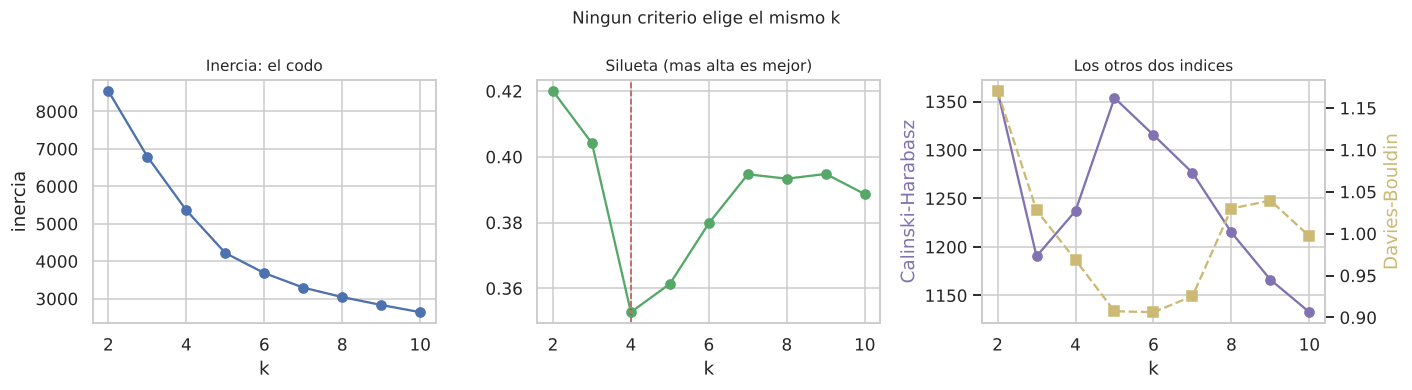

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(indices.index, indices.inercia, "o-", color="#4C72B0")
axes[0].set_title("Inercia: el codo", fontsize=10)
axes[0].set_xlabel("k"); axes[0].set_ylabel("inercia")

axes[1].plot(indices.index, indices.silueta, "o-", color="#55A868")
axes[1].axvline(4, color="#C44E52", ls="--", lw=1)
axes[1].set_title("Silueta (mas alta es mejor)", fontsize=10)
axes[1].set_xlabel("k")

ax2 = axes[2]
ax2.plot(indices.index, indices.Calinski_Harabasz, "o-", color="#8172B2", label="Calinski-Harabasz")
ax2.set_xlabel("k"); ax2.set_ylabel("Calinski-Harabasz", color="#8172B2")
ax3 = ax2.twinx()
ax3.plot(indices.index, indices.Davies_Bouldin, "s--", color="#CCB974", label="Davies-Bouldin")
ax3.set_ylabel("Davies-Bouldin", color="#CCB974")
ax3.grid(False)
ax2.set_title("Los otros dos indices", fontsize=10)

fig.suptitle("Ningun criterio elige el mismo k", fontsize=11)
plt.tight_layout(); plt.show()


**Los índices no coinciden.** La silueta y Calinski-Harabasz prefieren k=2, Davies-Bouldin prefiere
k=6, y la inercia no tiene un codo nítido: baja de forma suave, sin un quiebre que señale un número.

Y los dos que coinciden lo hacen en el valor menos útil: k=2 junta en un solo grupo todo lo que no
sea de baja intensidad, que es precisamente la estructura que queremos abrir.

Esto no es un defecto de los datos. Es la naturaleza del problema: **no hay una respuesta correcta**
porque no hay etiquetas contra las cuales comparar. Donde el aprendizaje supervisado tenía un error
que minimizar, acá tenemos cuatro números que miden cosas parecidas pero distintas, y ninguno es
*la* respuesta.

Hace falta entonces un criterio adicional que los índices no capturan.


# 8. El criterio que falta: estabilidad

Un agrupamiento sirve si **no depende del azar**. K-Means arranca de centros iniciales aleatorios, y
si distintos arranques terminan en agrupamientos distintos, los grupos son un artefacto del sorteo y
no una estructura de los datos.

Lo medimos con el **índice de Rand ajustado (ARI)**, que compara dos agrupamientos: vale 1 si son el
mismo y 0 si coinciden lo que coincidirían dos sorteos al azar. Corremos cada k con varias semillas y
miramos si llegan al mismo lugar.


In [14]:
def estabilidad(datos, k, n_init, semillas=range(6)):
    """ARI de cada semilla contra la primera: 1 es el mismo agrupamiento."""
    etiquetas = [KMeans(n_clusters=k, n_init=n_init, random_state=s).fit_predict(datos)
                 for s in semillas]
    return [adjusted_rand_score(etiquetas[0], e) for e in etiquetas[1:]]


filas = []
for n_init in [10, 200]:
    for k in range(2, 9):
        aris = estabilidad(X, k, n_init)
        filas.append({"n_init": n_init, "k": k, "ARI_minimo": min(aris),
                      "ARI_medio": np.mean(aris)})
est = pd.DataFrame(filas).pivot(index="k", columns="n_init",
                                values=["ARI_minimo", "ARI_medio"])
print("Estabilidad entre semillas, segun cuantos arranques prueba cada ajuste:\n")
print(est.to_string())


Estabilidad entre semillas, segun cuantos arranques prueba cada ajuste:

       ARI_minimo       ARI_medio      
n_init        10    200       10    200
k                                      
2           0.997 0.998     0.998 1.000
3           0.972 0.987     0.990 0.996
4           0.260 0.994     0.267 0.998
5           0.972 1.000     0.987 1.000
6           0.999 1.000     1.000 1.000
7           0.991 1.000     0.992 1.000
8           0.992 0.997     0.996 0.999


Acá aparece algo concreto y fácil de pasar por alto. Con `n_init=10` —que es un valor habitual— el
agrupamiento de **k=4 es inestable: ARI 0,26**, es decir que dos semillas distintas dan grupos casi
sin relación entre sí. Todos los demás k están arriba de 0,97.

No es que k=4 no tenga estructura: es que en k=4 hay **dos soluciones localmente óptimas** y con diez
arranques el algoritmo cae en una o en otra según la suerte. Se ve en la inercia, que es lo que
K-Means minimiza.


In [15]:
print("Inercia alcanzada por semilla, k=4:\n")
for n_init in [10, 200]:
    inercias = [KMeans(n_clusters=4, n_init=n_init, random_state=s).fit(X).inertia_
                for s in range(6)]
    print(f"  n_init={n_init:3d}: {[round(i, 1) for i in inercias]}")
print("\nCon 10 arranques algunas semillas se quedan en un optimo local peor (inercia mas alta).")
print("Con 200 arranques todas llegan al mismo minimo, y el agrupamiento se vuelve reproducible.")


Inercia alcanzada por semilla, k=4:

  n_init= 10: [5419.4, 5360.6, 5360.8, 5360.2, 5360.6, 5360.1]


  n_init=200: [5360.1, 5360.1, 5360.1, 5360.1, 5360.1, 5360.1]

Con 10 arranques algunas semillas se quedan en un optimo local peor (inercia mas alta).
Con 200 arranques todas llegan al mismo minimo, y el agrupamiento se vuelve reproducible.


La conclusión práctica es que **`n_init` no es un parámetro cosmético**: con 200 arranques, k=4 pasa
de ARI 0,26 a 0,99. Lo subimos para todo el notebook.

Es el equivalente no supervisado de lo que vimos en la Pre-entrega 3 con la semilla del bosque: hay
una parte del resultado que depende del azar del algoritmo y no de los datos, y hay que medirla antes
de interpretar nada.


# 9. La decisión: k = 4

Ningún índice elige k=4. Lo elegimos igual, y las razones son estas:

- **Estabilidad.** Con 200 arranques, los cuatro grupos se reproducen idénticos entre semillas.
- **Tamaños utilizables.** El grupo más chico tiene 84 pozos. Con k=2 se pierde toda la estructura
  interna; con k≥5 los grupos empiezan a ser subdivisiones del mismo tipo de diseño.
- **Interpretabilidad.** Es el k más alto en el que cada grupo corresponde a una forma distinta y
  reconocible de completar un pozo. Lo mostramos en el punto 10: en k=5 el grupo grande se parte en
  dos que tienen prácticamente el mismo perfil.
- **Davies-Bouldin casi no lo castiga:** 0,969 contra un mínimo de 0,906 en k=6. En
  Calinski-Harabasz k=4 sí queda por debajo de k=2 y k=5, y lo asumimos: es el precio de partir el
  grupo grande en familias que se pueden nombrar.

Es una decisión argumentada, no una lectura automática de un número. En aprendizaje no supervisado es
el caso normal: **el criterio final lo pone el analista**, y lo que corresponde es dejarlo escrito.


In [16]:
K = 4
modelo = KMeans(n_clusters=K, n_init=200, random_state=SEMILLA).fit(X)
pozos["grupo"] = modelo.labels_

# Nombres por perfil, no por numero de etiqueta: asi el notebook no depende de en que
# orden K-Means haya numerado los grupos.
mediana = pozos.groupby("grupo")[INTENSIDAD].median()
nombres = {}
importada = mediana.ratio_arena_importada.idxmax()
nombres[importada] = "arena importada"
resto = mediana.drop(index=importada).agua_por_metro.sort_values()
for etiqueta, nombre in zip(resto.index, ["baja intensidad", "intermedio", "intensivo moderno"]):
    nombres[etiqueta] = nombre

ORDEN = ["intensivo moderno", "intermedio", "arena importada", "baja intensidad"]
pozos["familia"] = pd.Categorical(pozos.grupo.map(nombres), categories=ORDEN, ordered=True)

print(f"Silueta del modelo elegido: {silhouette_score(X, modelo.labels_):.3f}")
print(f"Estabilidad (ARI minimo entre 6 semillas): {min(estabilidad(X, K, 200)):.3f}\n")
print(pozos.familia.value_counts().reindex(ORDEN).to_string())


Silueta del modelo elegido: 0.353


Estabilidad (ARI minimo entre 6 semillas): 0.994

familia
intensivo moderno    1476
intermedio            911
arena importada       132
baja intensidad        84


# Parte 4: Qué encontró el algoritmo

# 10. El perfil de las cuatro familias

Acá está el resultado central. Cada fila es una familia de diseño; cada columna, la mediana de una
variable dentro de esa familia. Las dos últimas columnas —rama y etapas— **no entraron al ajuste**:
sirven para describir lo que el algoritmo encontró mirando solo las cinco de intensidad.


In [17]:
perfil = pozos.groupby("familia", observed=True)[INTENSIDAD + DESCRIPTIVAS].median()
perfil.insert(0, "pozos", pozos.familia.value_counts().reindex(ORDEN))
perfil["%"] = (perfil.pozos / perfil.pozos.sum() * 100).round(1)
print(perfil.to_string())


                   pozos  espaciamiento_etapas_m  arena_por_metro  agua_por_metro  ratio_agua_arena  ratio_arena_importada  longitud_rama_horizontal_m  cantidad_fracturas  anio_fractura      %
familia                                                                                                                                                                                         
intensivo moderno   1476                  60.055            3.912          24.800             6.473                  0.000                       2,800              48.000          2,024 56.700
intermedio           911                  75.683            3.014          18.389             6.057                  0.000                       2,256              29.000          2,020 35.000
arena importada      132                  78.123            2.822          13.625             5.220                  0.896                       1,244              15.000          2,016  5.100
baja intensidad       84           

Las cuatro familias se leen solas:

| Familia | Cómo se reconoce |
|---|---|
| **Intensivo moderno** | La receta actual: rama de 2.800 m, 48 etapas cada 60 m, 3,9 t de arena y 24,8 m³ de agua por metro. Mediana de año 2024 |
| **Intermedio** | La misma idea a menor escala: rama de 2.256 m, 29 etapas cada 76 m, menos arena y menos agua por metro. Mediana de año 2020 |
| **Arena importada** | Se distingue por el abastecimiento, no por la geometría: **90% de arena importada**. Rama corta, 15 etapas. Mediana de año 2016 |
| **Baja intensidad** | Pozos fracturados muy espaciado: 7 etapas cada 133 m, con 0,9 t de arena y 2,6 m³ de agua por metro, diez veces menos que el resto |

**El algoritmo no vio el año de fractura** y sin embargo las medianas de año salen ordenadas: 2024,
2020, 2016, 2017. Lo que encontró, sin que se lo pidiéramos, es la **evolución histórica del diseño
de completación** en Vaca Muerta — el mismo fenómeno que habíamos descrito a mano en el análisis
exploratorio de la Pre-entrega 2.


In [18]:
# Por que no k=5: el grupo grande se parte en dos con el mismo perfil.
km5 = KMeans(n_clusters=5, n_init=200, random_state=SEMILLA).fit(X)
perfil5 = pozos.assign(g5=km5.labels_).groupby("g5")[INTENSIDAD + DESCRIPTIVAS].median()
perfil5.insert(0, "pozos", pd.Series(km5.labels_).value_counts().sort_index())
print("Con k=5, para comparar:\n")
print(perfil5.sort_values("agua_por_metro", ascending=False).to_string())


Con k=5, para comparar:

    pozos  espaciamiento_etapas_m  arena_por_metro  agua_por_metro  ratio_agua_arena  ratio_arena_importada  longitud_rama_horizontal_m  cantidad_fracturas  anio_fractura
g5                                                                                                                                                                        
0     666                  57.969            3.951          29.479             7.383                  0.000                       2,800              49.000          2,024
4    1047                  60.829            3.868          22.945             5.975                  0.000                       2,744              45.000          2,024
2     681                  78.317            2.934          17.999             6.361                  0.000                       2,074              27.000          2,018
3     131                  77.967            2.837          13.706             5.062                  0.895             

Los dos grupos más grandes de k=5 tienen rama de 2.800 y 2.744 m, 49 y 45 etapas, 3,95 y 3,87 t/m de
arena. Son **el mismo diseño partido en dos** por una diferencia de agua por metro. Ganamos un poco
de Calinski-Harabasz y perdemos una familia interpretable: por eso nos quedamos en k=4.


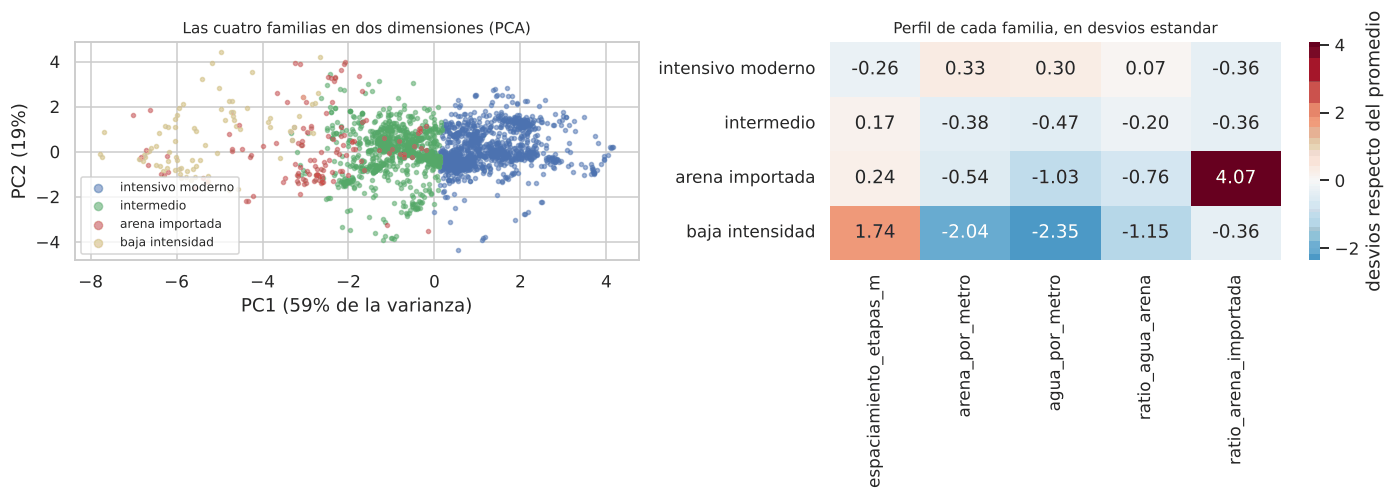

Peso de cada variable en las dos componentes principales:
                          PC1    PC2
espaciamiento_etapas_m -0.502  0.289
arena_por_metro         0.504 -0.419
agua_por_metro          0.555  0.190
ratio_agua_arena        0.328  0.835
ratio_arena_importada  -0.281  0.085


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

pca = PCA(n_components=2, random_state=SEMILLA).fit(X)
Z = pca.transform(X)
colores = {"intensivo moderno": "#4C72B0", "intermedio": "#55A868",
           "arena importada": "#C44E52", "baja intensidad": "#CCB974"}
for nombre in ORDEN:
    sel = (pozos.familia == nombre).to_numpy()
    axes[0].scatter(Z[sel, 0], Z[sel, 1], s=7, alpha=0.5, label=nombre, color=colores[nombre])
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[0].set_title("Las cuatro familias en dos dimensiones (PCA)", fontsize=10)
axes[0].legend(fontsize=8, markerscale=2)

z = ((perfil[INTENSIDAD] - pozos[INTENSIDAD].mean()) / pozos[INTENSIDAD].std())
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1],
            cbar_kws={"label": "desvios respecto del promedio"})
axes[1].set_title("Perfil de cada familia, en desvios estandar", fontsize=10)
axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

print("Peso de cada variable en las dos componentes principales:")
print(pd.DataFrame(pca.components_.T, index=INTENSIDAD, columns=["PC1", "PC2"]).to_string())


# 11. Las familias en el tiempo y por operadora

Si la hipótesis de que los grupos son generaciones de diseño es correcta, el reparto por año tiene
que mostrarlo con claridad.


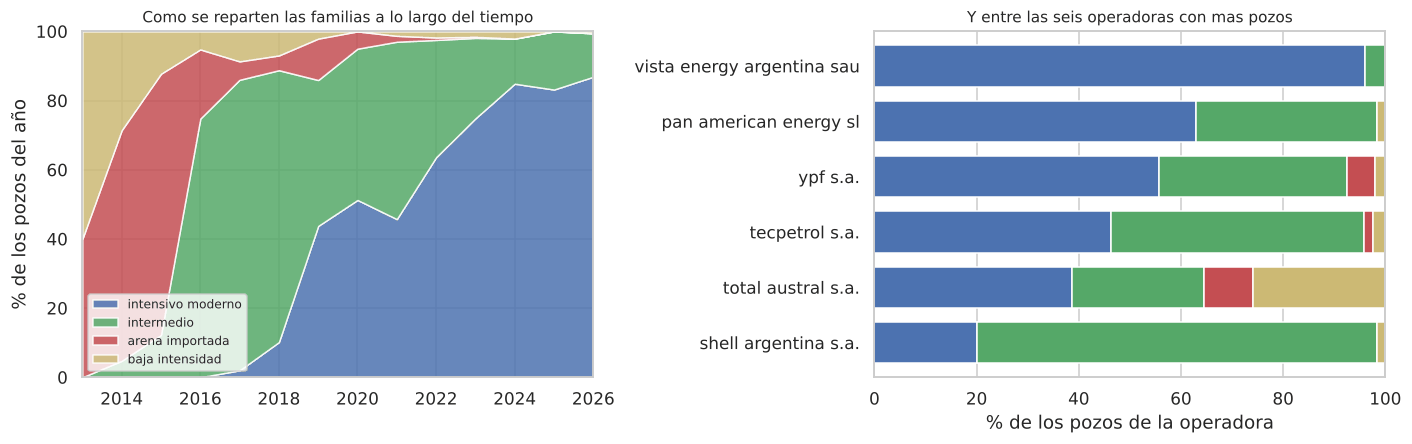

familia        intensivo moderno  intermedio  arena importada  baja intensidad
anio_fractura                                                                 
2013                           0           0               40               60
2014                           0           5               67               29
2015                           0          12               76               12
2016                           0          75               20                5
2017                           2          84                5                9
2018                          10          79                4                7
2019                          44          42               12                2
2020                          51          44                5                0
2021                          46          51                2                1
2022                          64          34                1                2
2023                          75          23        

In [20]:
anios = pozos[pozos.anio_fractura.notna() & (pozos.anio_fractura >= 2013)]
reparto = pd.crosstab(anios.anio_fractura.astype(int), anios.familia, normalize="index") * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].stackplot(reparto.index, [reparto[c] for c in ORDEN],
                  labels=ORDEN, colors=[colores[c] for c in ORDEN], alpha=0.85)
axes[0].set_xlim(reparto.index.min(), reparto.index.max())
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("% de los pozos del año")
axes[0].set_title("Como se reparten las familias a lo largo del tiempo", fontsize=10)
axes[0].legend(fontsize=8, loc="lower left")

top = pozos.operadora.value_counts().head(6).index
porop = (pd.crosstab(pozos.loc[pozos.operadora.isin(top), "operadora"],
                     pozos.loc[pozos.operadora.isin(top), "familia"],
                     normalize="index") * 100)
porop = porop[ORDEN].sort_values("intensivo moderno")
porop.plot(kind="barh", stacked=True, ax=axes[1],
           color=[colores[c] for c in ORDEN], legend=False, width=0.75)
axes[1].set_xlabel("% de los pozos de la operadora")
axes[1].set_ylabel("")
axes[1].set_title("Y entre las seis operadoras con mas pozos", fontsize=10)
plt.tight_layout(); plt.show()

print(reparto.round(0).astype(int).to_string())


El gráfico de la izquierda es la historia de Vaca Muerta contada por un algoritmo que nunca vio una
fecha: la familia de baja intensidad y la de arena importada dominan hasta 2015, el diseño intermedio
se impone entre 2016 y 2019, y el intensivo moderno pasa de no existir a ser cuatro de cada cinco
pozos.

A la derecha se ve que **las operadoras no son intercambiables**: hay empresas con casi todos sus
pozos en la familia moderna y otras repartidas. Vale la misma advertencia de las entregas anteriores
—cada operadora trabaja en áreas distintas, así que esto mezcla estrategia con geología y con el
momento en que a cada una le tocó perforar.


# Parte 5: Comparación y validación

# 12. ¿Y si usamos otro algoritmo?

K-Means impone grupos esféricos y de tamaño parecido. Antes de quedarnos con su respuesta, probamos
otras tres familias de algoritmos sobre exactamente los mismos datos:

- **Ward (jerárquico aglomerativo):** empieza con cada pozo en su propio grupo y va uniendo los dos
  que menos aumentan la varianza. No asume forma esférica.
- **Mezcla de gaussianas (GMM):** permite grupos elipsoidales y asignación probabilística.
- **DBSCAN:** agrupa por densidad y, a diferencia de los otros tres, **puede declarar que un punto no
  pertenece a ningún grupo**. No hay que decirle cuántos grupos buscar.


In [21]:
comparacion = []
etiquetas_km = modelo.labels_
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
gmm = GaussianMixture(n_components=K, random_state=SEMILLA, n_init=10).fit(X)
etiquetas_gmm = gmm.predict(X)

for nombre, lab in [("K-Means", etiquetas_km), ("Ward", ward.labels_), ("GMM", etiquetas_gmm)]:
    comparacion.append({
        "algoritmo": nombre,
        "silueta": silhouette_score(X, lab),
        "Calinski_Harabasz": calinski_harabasz_score(X, lab),
        "Davies_Bouldin": davies_bouldin_score(X, lab),
        "grupo_mas_chico": pd.Series(lab).value_counts().min(),
        "ARI_vs_KMeans": adjusted_rand_score(etiquetas_km, lab)})
print(f"Los tres con k={K}, sobre los mismos datos:\n")
print(pd.DataFrame(comparacion).set_index("algoritmo").to_string())


Los tres con k=4, sobre los mismos datos:

           silueta  Calinski_Harabasz  Davies_Bouldin  grupo_mas_chico  ARI_vs_KMeans
algoritmo                                                                            
K-Means      0.353              1,237           0.969               84          1.000
Ward         0.334              1,146           0.996               90          0.258
GMM          0.090            322.457           3.100              265          0.172


In [22]:
print("DBSCAN: no se le dice cuantos grupos, se le dice que tan cerca tienen que estar.\n")
filas = []
for eps in [0.4, 0.6, 0.8, 1.0, 1.2]:
    db = DBSCAN(eps=eps, min_samples=10).fit(X)
    sin_ruido = db.labels_ != -1
    n_grupos = len(set(db.labels_[sin_ruido]))
    filas.append({
        "eps": eps, "grupos": n_grupos,
        "pozos_sin_grupo": int((~sin_ruido).sum()),
        "%_sin_grupo": (~sin_ruido).mean() * 100,
        "silueta_sin_ruido": (silhouette_score(X[sin_ruido], db.labels_[sin_ruido])
                              if n_grupos > 1 else np.nan)})
print(pd.DataFrame(filas).set_index("eps").to_string())


DBSCAN: no se le dice cuantos grupos, se le dice que tan cerca tienen que estar.



       grupos  pozos_sin_grupo  %_sin_grupo  silueta_sin_ruido
eps                                                           
0.400       7              537       20.630             -0.164
0.600       5              325       12.486              0.317
0.800       4              204        7.837              0.585
1.000       4              133        5.109              0.574
1.200       3               82        3.150              0.574


**K-Means gana, pero no por goleada, y los tres no encuentran lo mismo.** El ARI de K-Means contra
Ward es bajo: los dos ven cuatro grupos de tamaños parecidos, pero no ponen las fronteras en el mismo
lugar. GMM queda bastante peor en los tres índices, lo que es esperable: nuestras variables no se
parecen a mezclas de gaussianas, sobre todo `ratio_arena_importada`, que está amontonada en 0 y en 1.

DBSCAN merece un párrafo aparte. Con un radio chico declara sin grupo a uno de cada cinco pozos; con
un radio grande junta casi todo en un solo grupo y deja afuera a los raros. En el medio llega a una
silueta alta, **pero a costa de no clasificar a un 8% de los pozos**. Para un problema donde queremos
una tipología que cubra a todos los pozos, eso es una desventaja, no una virtud — aunque confirma
algo útil: los pozos que DBSCAN no logra agrupar son, otra vez, los extremos del punto 5.


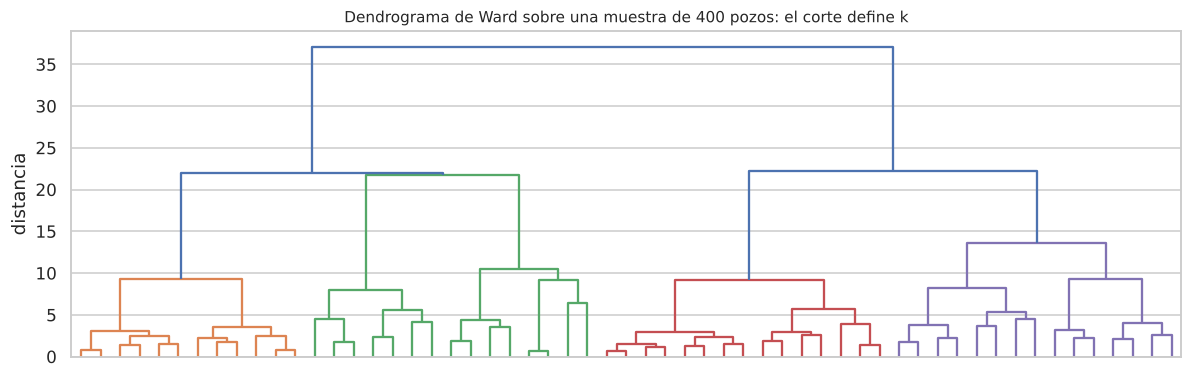

In [23]:
# El dendrograma muestra la estructura jerarquica completa: donde cortarlo es la eleccion de k.
enlaces = linkage(X[np.random.default_rng(SEMILLA).choice(len(X), 400, replace=False)],
                  method="ward")
fig, ax = plt.subplots(figsize=(11, 3.6))
dendrogram(enlaces, truncate_mode="level", p=5, no_labels=True, ax=ax,
           color_threshold=enlaces[-3, 2])
ax.set_title("Dendrograma de Ward sobre una muestra de 400 pozos: el corte define k",
             fontsize=10)
ax.set_ylabel("distancia")
plt.tight_layout(); plt.show()


# 13. La validación que importa: ¿las familias producen distinto?

Hasta acá todo lo que medimos es interno: cuán compactos y separados son los grupos. Pero tenemos una
carta guardada. **La producción nunca entró al ajuste**, así que podemos usarla como validación
externa, que es lo más parecido a una prueba objetiva que admite un problema no supervisado.

La pregunta es directa: si las familias son algo real y no un corte arbitrario del espacio, los pozos
de familias distintas deberían producir distinto.


In [24]:
con_prod = pozos[pozos.prod_pet_acum_12m.notna() & (pozos.es_pozo_de_gas == 0)]
print(f"Pozos con produccion medida: {len(con_prod):,} de {len(pozos):,}\n")

tabla = con_prod.groupby("familia", observed=True).prod_pet_acum_12m.agg(
    pozos="size", mediana="median", media="mean", q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75)).reindex(ORDEN)
print(tabla.to_string())

muestras = [g.prod_pet_acum_12m.values for _, g in con_prod.groupby("familia", observed=True)]
h, p_valor = kruskal(*muestras)
print(f"\nKruskal-Wallis: H = {h:,.1f}   p = {p_valor:.2e}")
print("(contrasta si las cuatro distribuciones tienen la misma mediana; p chico = no la tienen)")


Pozos con produccion medida: 1,917 de 2,603

                   pozos  mediana  media     q1     q3
familia                                               
intensivo moderno   1078   36,760 36,725 24,801 47,569
intermedio           716   26,422 26,608 15,230 36,226
arena importada       92   15,638 18,573  9,601 21,670
baja intensidad       31    3,311  8,981  1,461 15,047

Kruskal-Wallis: H = 264.4   p = 4.99e-57
(contrasta si las cuatro distribuciones tienen la misma mediana; p chico = no la tienen)


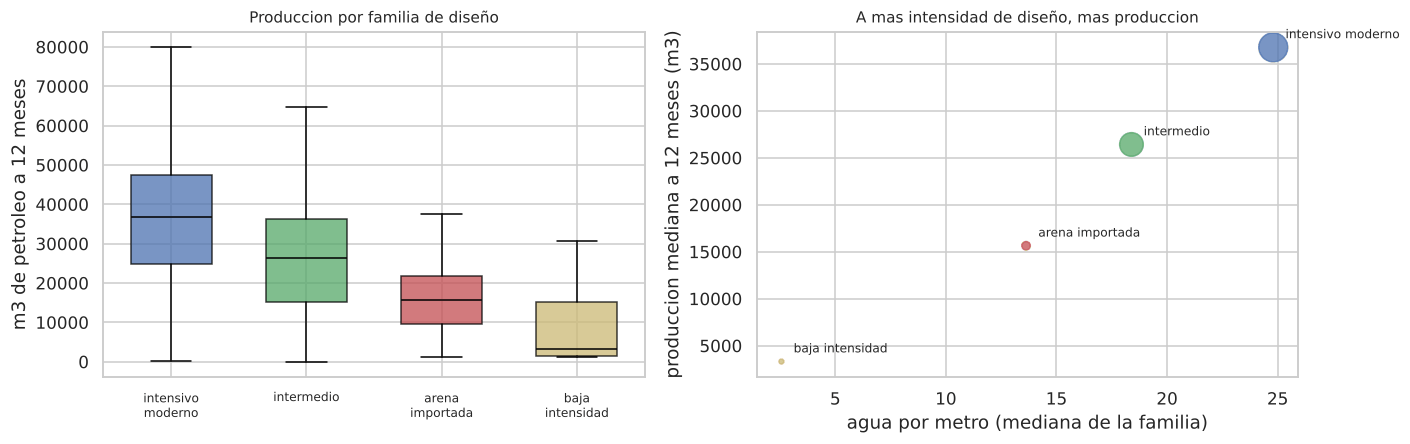

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

datos_caja = [con_prod.loc[con_prod.familia == n, "prod_pet_acum_12m"] for n in ORDEN]
caja = axes[0].boxplot(datos_caja, tick_labels=[n.replace(" ", "\n") for n in ORDEN],
                       patch_artist=True, showfliers=False, widths=0.6)
for parche, nombre in zip(caja["boxes"], ORDEN):
    parche.set_facecolor(colores[nombre]); parche.set_alpha(0.75)
for mediana_ in caja["medians"]:
    mediana_.set_color("black")
axes[0].set_ylabel("m3 de petroleo a 12 meses")
axes[0].set_title("Produccion por familia de diseño", fontsize=10)
axes[0].tick_params(axis="x", labelsize=8)

orden_int = perfil.loc[ORDEN, "agua_por_metro"]
axes[1].scatter(orden_int, tabla.mediana, s=tabla.pozos / 3, alpha=0.75,
                color=[colores[n] for n in ORDEN])
for nombre in ORDEN:
    axes[1].annotate(nombre, (orden_int[nombre], tabla.mediana[nombre]),
                     textcoords="offset points", xytext=(8, 6), fontsize=8)
axes[1].set_xlabel("agua por metro (mediana de la familia)")
axes[1].set_ylabel("produccion mediana a 12 meses (m3)")
axes[1].set_title("A mas intensidad de diseño, mas produccion", fontsize=10)
plt.tight_layout(); plt.show()


**Las cuatro familias producen distinto, y en el orden que predice la intensidad del diseño.** La
mediana va de 36.760 m³ en la familia intensiva a 3.311 m³ en la de baja intensidad: un factor de
once. El contraste de Kruskal-Wallis descarta que sea casualidad por un margen enorme.

Conviene ser preciso sobre qué prueba esto y qué no:

- **Sí prueba** que los grupos no son un corte arbitrario: capturan una diferencia real que se
  manifiesta en una variable que el algoritmo nunca vio.
- **No prueba** que el diseño cause la producción. Las familias están fuertemente correlacionadas con
  la época, y entre 2015 y 2024 no cambió solo el diseño: cambió también dónde se perfora, con qué
  conocimiento del reservorio y con qué equipos. Es la misma limitación de las entregas anteriores,
  y acá es más fuerte todavía porque no hay ningún control.

La lectura honesta es que **estas cuatro familias son una forma compacta de describir cómo se
completaron los pozos de Vaca Muerta en quince años**, y que esa descripción se corresponde con
diferencias grandes de productividad.


# 14. Conclusiones

## Lo que encontramos

**Los pozos se agrupan solos en cuatro familias de diseño.** No hubo que proponer las categorías: con
las cinco variables de intensidad y nada más, K-Means separa un diseño intensivo moderno (1.476
pozos), uno intermedio (911), uno definido por el uso de arena importada (132) y uno de baja
intensidad (84).

**Las familias reconstruyen la historia del diseño sin ver una sola fecha.** Las medianas de año
salen 2024, 2020, 2016 y 2017, y el reparto anual muestra el reemplazo de una generación por otra.
Es el mismo fenómeno que describimos a mano en la Pre-entrega 2, encontrado esta vez por un algoritmo
que solo miraba la receta de fractura.

**Las familias ordenan la producción sin haberla visto.** De 36.760 m³ de mediana a 3.311 m³, en el
mismo orden que la intensidad del diseño. Como la producción quedó fuera del ajuste, es una
validación externa genuina.

**Una variable inútil para predecir puede ser decisiva para describir.** `ratio_arena_importada` es
la variable que los modelos supervisados descartaron: +79 m³ en Ridge e importancia **0,0000 exacta**
en el clasificador. Acá define una familia entera. No hay contradicción: predecir la producción y
describir el diseño son preguntas distintas, y una variable puede ser irrelevante para una y central
para la otra.

## Lo que aprendimos del método

**Las métricas internas premian aislar extremos.** Sin acotar los valores extremos, K-Means dedicaba
un grupo entero a **tres pozos** y la silueta lo aplaudía con un 0,62. Al acotarlos cayó a 0,40, con
un grupo más chico de 134 pozos en lugar de 3. Es la tercera vez en el proyecto que nos encontramos con lo mismo: la Pre-entrega 3
con la partición aleatoria, después con el año de fractura, y ahora acá. **Una métrica que mejora
merece desconfianza hasta entender qué está premiando.**

**Los índices de validación no alcanzan para decidir.** Silueta y Calinski-Harabasz votan k=2,
Davies-Bouldin vota k=6, la inercia no vota nada: ninguno elige el k que termina siendo interpretable.
En un problema sin respuesta correcta el criterio final lo pone el analista, y lo que corresponde es
dejarlo argumentado por escrito.

**`n_init` no es un parámetro decorativo.** Con 10 arranques, k=4 daba agrupamientos distintos según
la semilla (ARI 0,26). Con 200, el mismo siempre (ARI 0,99). La diferencia entre un resultado
reproducible y uno que no lo es estaba en un argumento que es fácil dejar en su valor por defecto.

## Limitaciones

| Limitación | Alcance |
|---|---|
| **Las familias están confundidas con la época** | no se puede separar el efecto del diseño del de todo lo demás que cambió en quince años |
| **k=4 es una decisión, no un hallazgo** | con otro criterio razonable se podría defender k=5 o k=6, y los grupos serían otros |
| **El recorte al 1%–99% borra diferencias reales** | un pozo de espaciamiento 1.123 m queda indistinguible de uno de 146 m |
| **Dos familias son chicas** | 132 y 84 pozos, y de esos solo 92 y 31 tienen producción medida: las comparaciones sobre esas familias son frágiles |
| **Sigue sin haber geología** | la misma limitación de todo el proyecto. Dos pozos con la misma receta en áreas distintas caen en la misma familia y pueden producir muy distinto |


---

## Datos usados en esta entrega

| Archivo | Origen | Contenido |
|---|---|---|
| `data/fractura_adjunto_iv.csv` | Secretaría de Energía — Adjunto IV | diseño de completación, 4.890 registros |
| `data/produccion_filtrada.csv.gz` | Secretaría de Energía — Producción por pozo y mes | 136.380 registros de pozo-mes, usado solo para validar |

**Proyecto Final — EnergIA Digital 2026 · Ciencia de Datos**

Franco Malacalza · Martín Gerbaldo · Carolina Bailón
